# Example of the aitlas toolbox in the context of object detection in remote sensing images

This subset of COWC contains single pixel labels used originally for a counting task. We here showcase an example where the pixels are translated into a bounding box for object detection.

## Import the required packages

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning) 
warnings.filterwarnings("ignore", category=DeprecationWarning) 

from aitlas.datasets import COWCObjectDetectionDataset 
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects with bounding boxes

Total number of patches: 2028


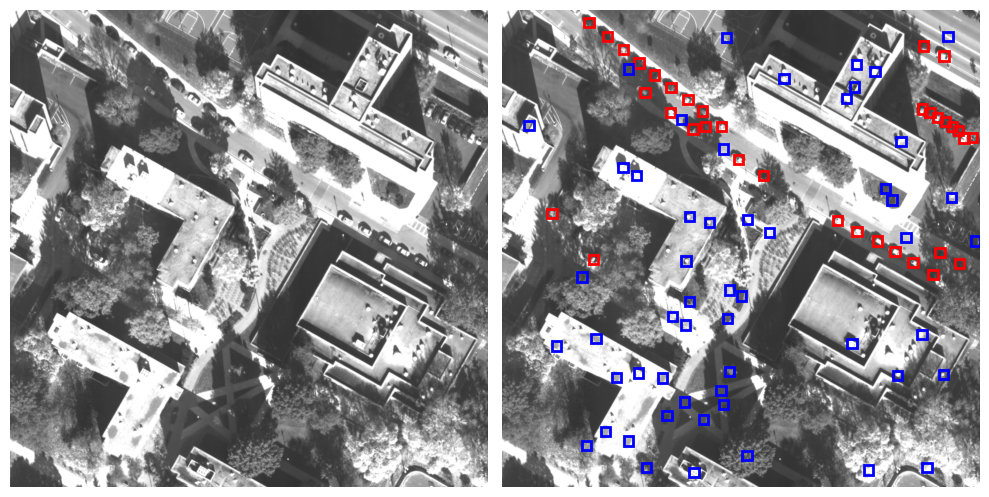

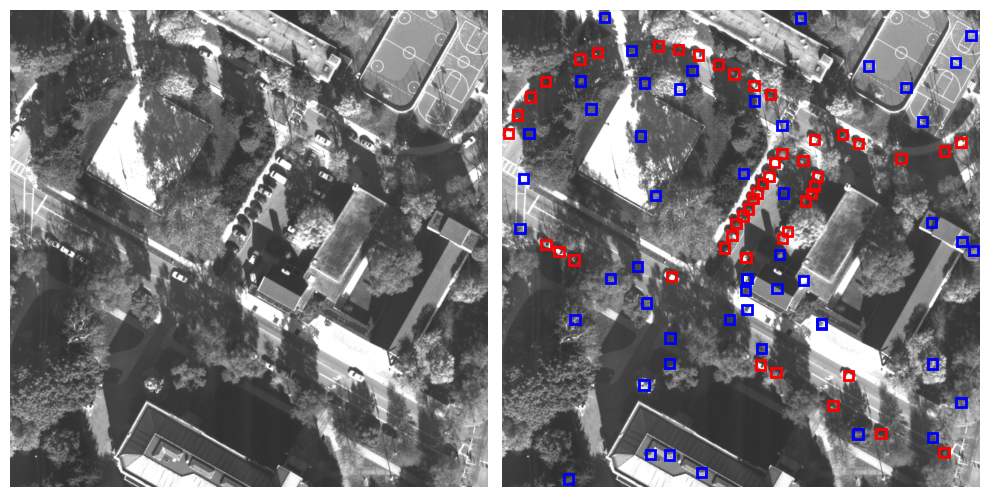

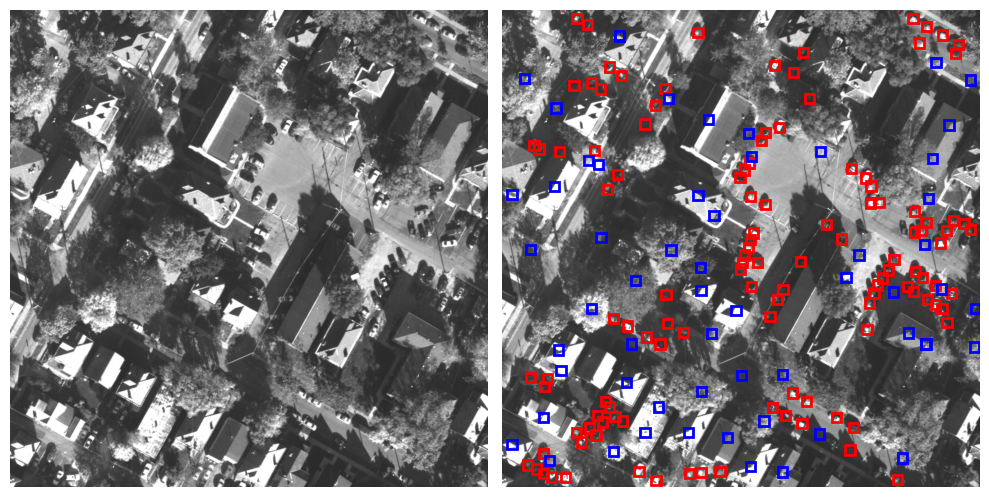

In [ ]:
dataset_config = {
    "data_dir": "./data/cowc_object_detection/datasets/ground_truth_sets/",

}
dataset = COWCObjectDetectionDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}") # the 32 original images are split into 2028 image patches
dataset.show_image(1);
dataset.show_image(5);
dataset.show_image(7);

In [63]:
dataset.data_distribution_table()

,Count
negative,69537.0
car,37669.0


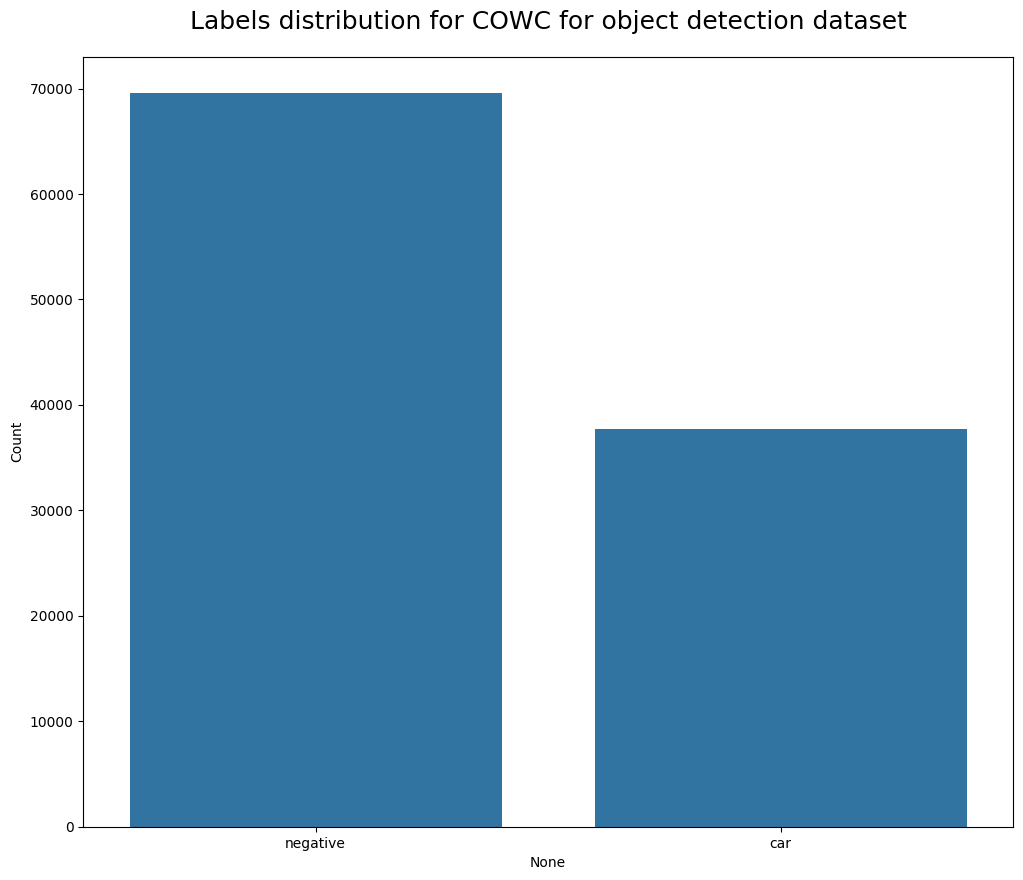

In [64]:
dataset.data_distribution_barchart();

## Load train data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "data_dir": "./data/cowc_object_detection/datasets/ground_truth_sets/",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = COWCObjectDetectionDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 2028


## Create the model

In [ ]:
epochs = 10
model_directory = "./data/experiments/COWC_object_detection"
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [17]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-10-10 07:55:13,374 INFO Starting training.
training: 100%|██████████| 254/254 [01:41<00:00,  2.51it/s]
2025-10-10 07:56:54,689 INFO epoch: 1, time: 101, loss:  0.65480
testing on train set: 100%|██████████| 254/254 [01:33<00:00,  2.73it/s]
2025-10-10 07:59:42,626 INFO map:0.16809287667274475, map_50:0.32175618410110474, map_75:0.15464036166667938, map_small:0.16809287667274475, map_medium:-1.0, map_large:-1.0, mar_1:0.010582002811133862, mar_10:0.07330609858036041, mar_100:0.20421923696994781, mar_small:0.20421923696994781, mar_medium:-1.0, mar_large:-1.0, map_per_class:tensor(0.), tensor(0.3362), mar_100_per_class:tensor(0.), tensor(0.4084), classes:tensor(0, dtype=torch.int32), tensor(1, dtype=torch.int32)
training: 100%|██████████| 254/254 [01:37<00:00,  2.61it/s]
2025-10-10 08:01:19,945 INFO epoch: 2, time: 97, loss:  0.44326
testing on train set: 100%|██████████| 254/254 [01:31<00:00,  2.79it/s]
2025-10-10 08:03:45,712 INFO map:0.18099422752857208, map_50:0.3461591303348541, 

## Predictions

2025-10-10 08:42:42,241 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/COWC_object_detection/checkpoint.pth.tar


2025-10-10 08:42:42,559 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/COWC_object_detection/checkpoint.pth.tar at epoch 11


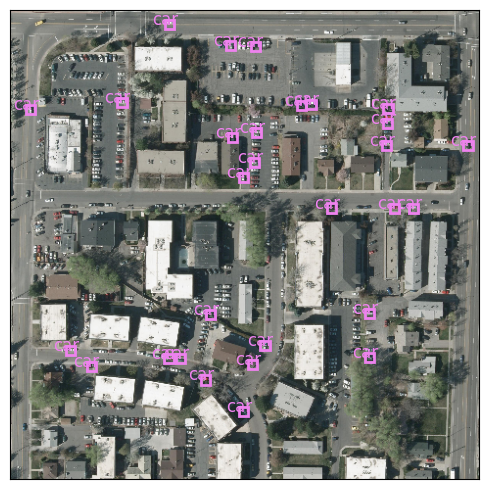

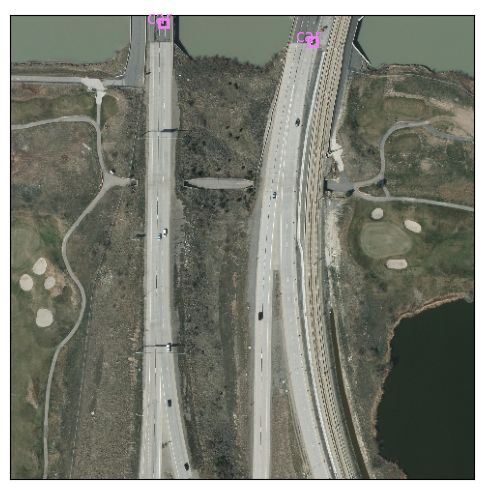

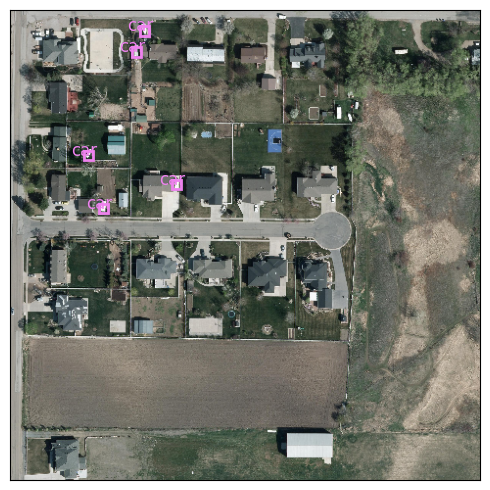

In [ ]:
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "./data/experiments/COWC_object_detection/checkpoint.pth.tar"
labels = ["negative", "car"]
transform = Resize()
model.load_model(model_path)

image = image_loader('./data/cowc_object_detection/datasets/testing_scenes/COWC_testing_scenes/testing_scenes/12TVK440540_CROP_01.png')
image = image[:,:,:3]
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/cowc_object_detection/datasets/testing_scenes/COWC_testing_scenes/testing_scenes/12TVL160120_CROP_s2.png')
image = image[:,:,:3]
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/cowc_object_detection/datasets/testing_scenes/COWC_testing_scenes/testing_scenes/12TVL240360_CROP_s1.png')
image = image[:,:,:3]
fig = model.detect_objects(image, labels, transform)